In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

We are using os and sys because by default jupyter work outside the project root so we need to make sure that it can also search the given path.

In [3]:
import os
import sys

sys.path.append(os.path.abspath("../.."))

from config import FEATURED_BTC_DATA_PATH

In [4]:
old_df = pd.read_csv(FEATURED_BTC_DATA_PATH)

In [5]:
old_df.shape

(34912, 56)

In [6]:
old_df.columns

Index(['timestamp', 'open', 'high', 'low', 'close', 'volume', 'quote_volume',
       'number_of_trades', 'taker_buy_base_volume', 'taker_buy_quote_volume',
       'taker_buy_ratio', 'fng_value', 'onchain_num_tx', 'onchain_hash_rate',
       'onchain_miners_revenue_usd', 'Price Change', 'Volatility',
       'high_low_ratio', 'close_open_diff', 'Rolling_Mean_Close',
       'Rolling_Std_Close', 'rolling_max_6h', 'rolling_min_6h', 'Target_Close',
       'Target_Movement', 'Target_Return', 'vol_1h', 'vol_mean_6h',
       'vol_std_6h', 'vol_max_6h', 'vol_min_6h', 'return_1h_lag',
       'return_mean_6h', 'return_std_6h', 'hour', 'dayofweek', 'day',
       'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'rsi', 'macd', 'bb_high',
       'bb_low', 'ema_10', 'ema_30', 'close_lag_1', 'volume_lag_1',
       'price_volatility_interaction', 'taker_buy_ratio_mean_6h',
       'trades_mean_6h', 'fng_mean_3d', 'onchain_num_tx_change',
       'onchain_hash_rate_change', 'onchain_miners_revenue_change'],
  

In [7]:
columns = old_df.select_dtypes(include = [np.number])

Here in heatmap we can see that there is one column is duplicate of other column also we can see column whose value are in dollers are in 0.99 to 1.0.

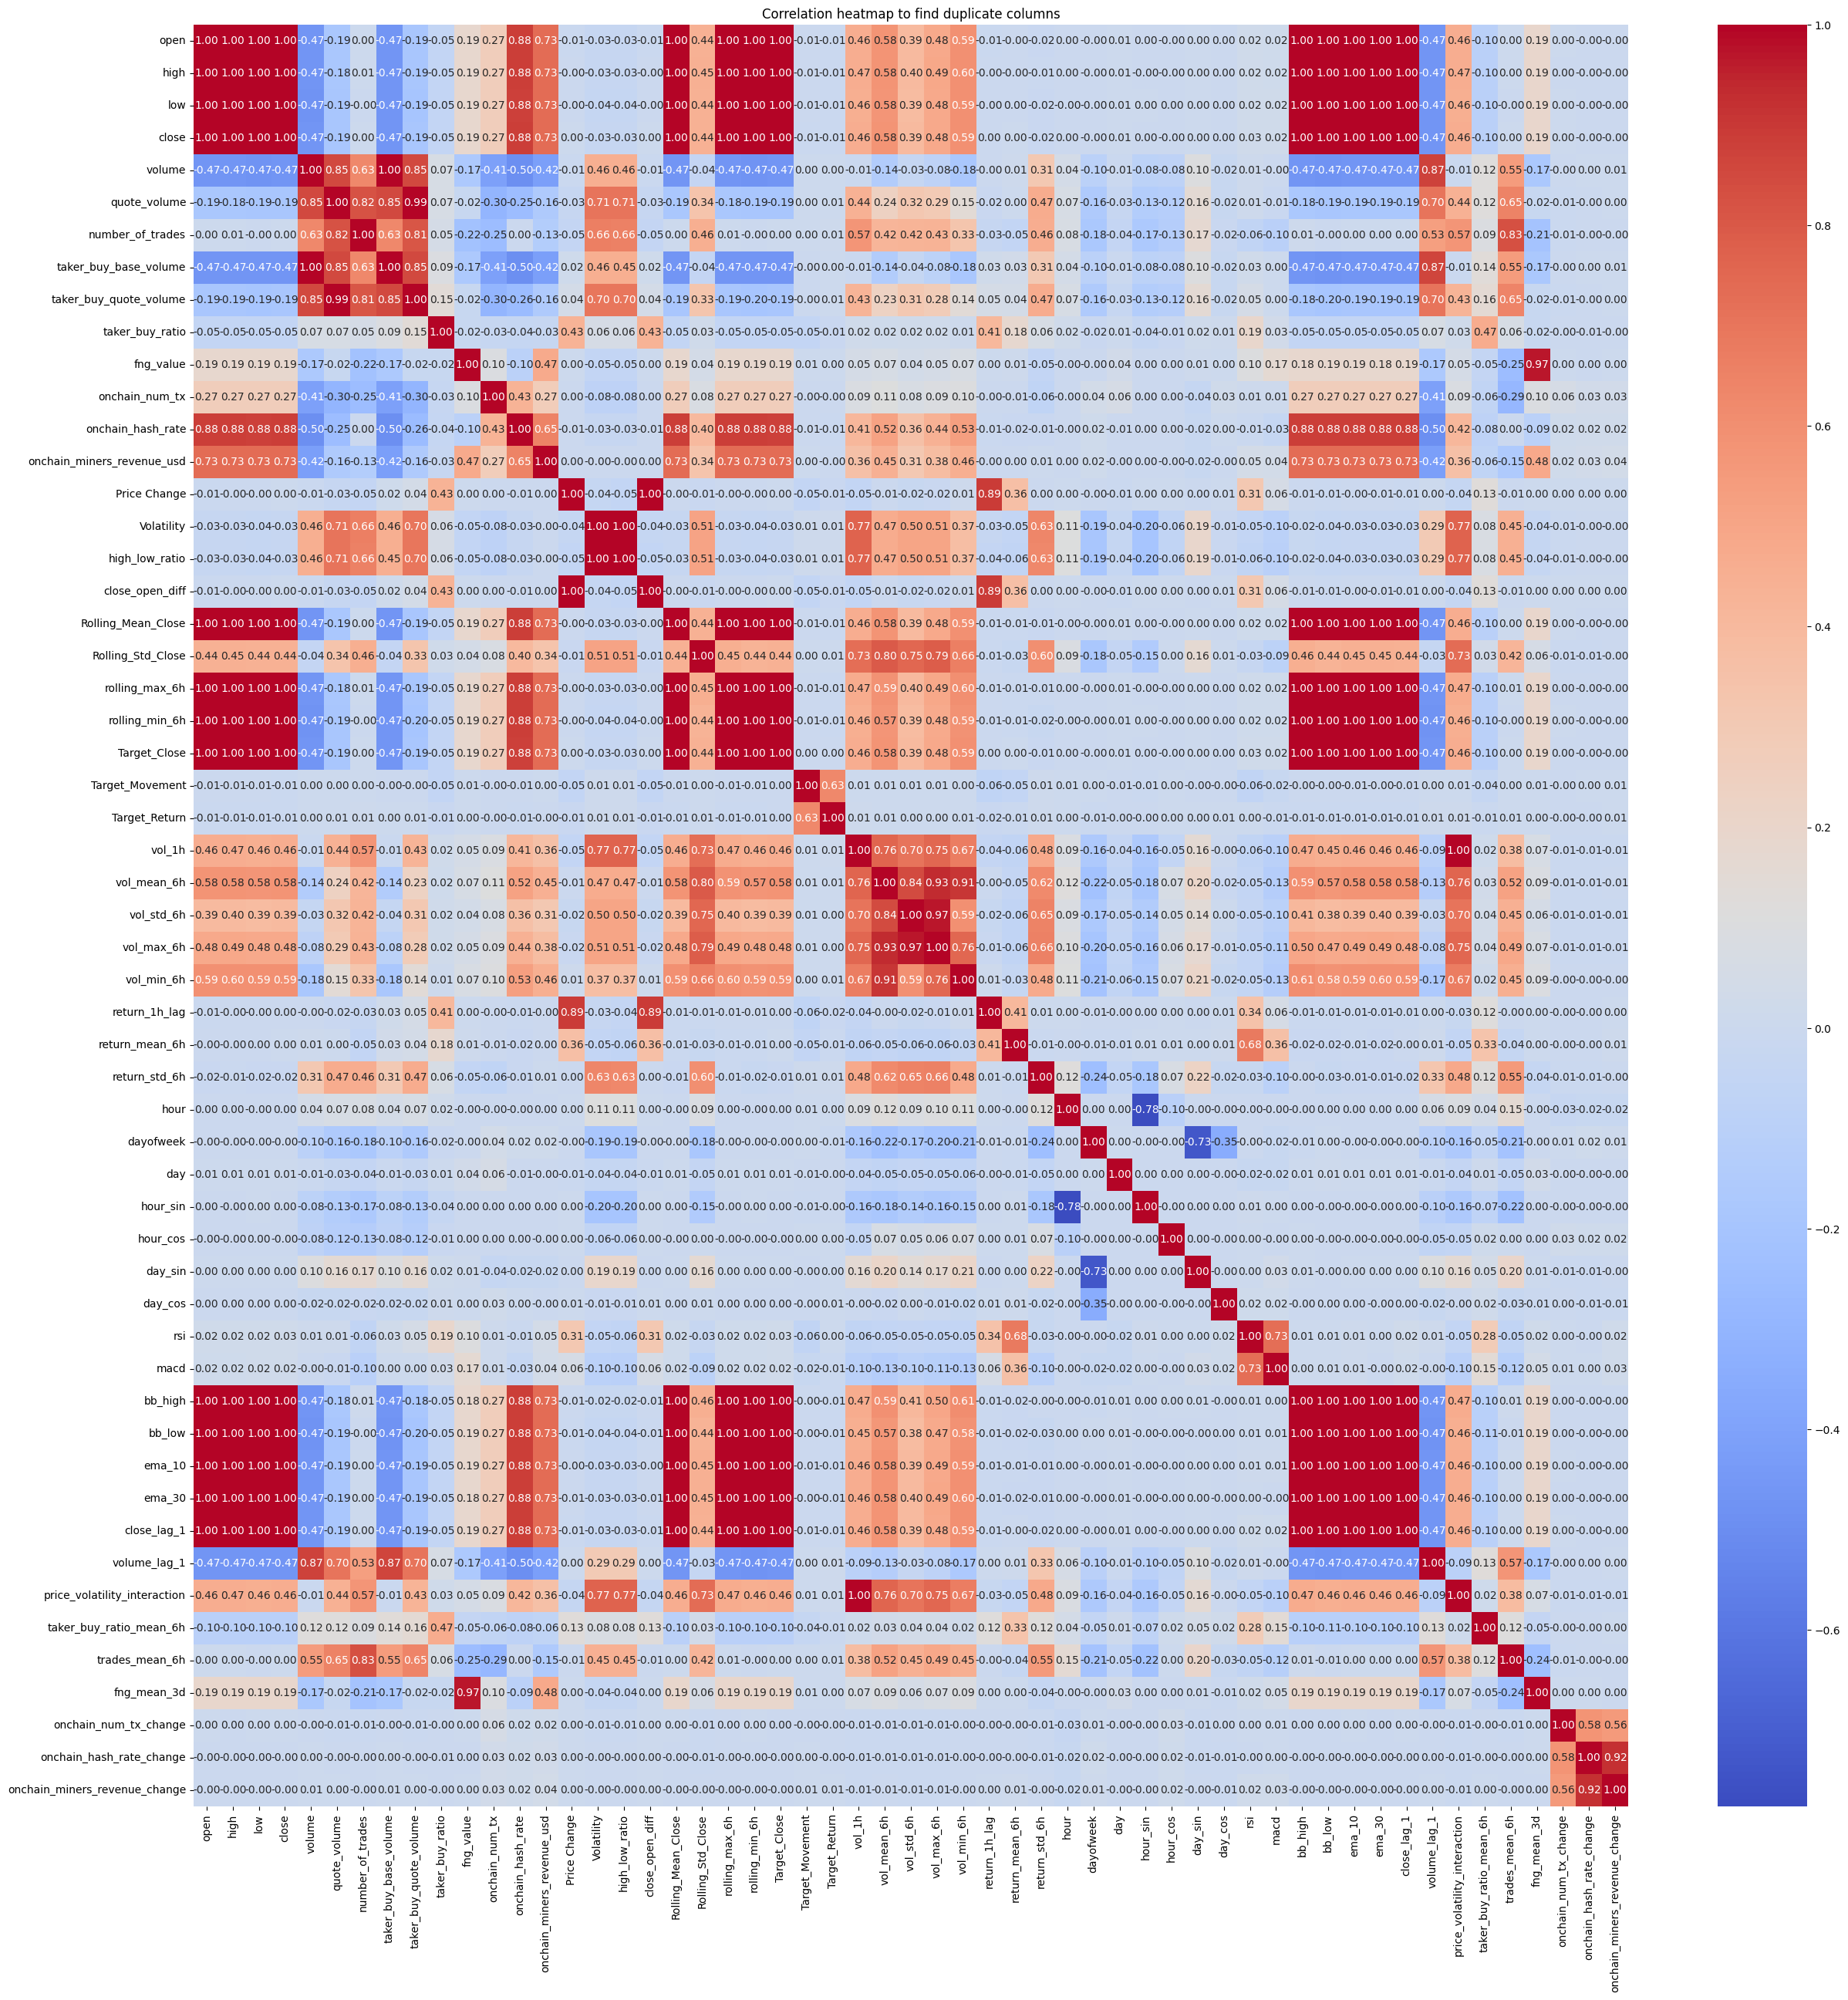

In [8]:
plt.figure(figsize = (30,30))
sb.heatmap(columns.corr(), annot = True, cmap = "coolwarm", fmt = ".2f")
plt.title("Correlation heatmap to find duplicate columns")
plt.show()

Here is we can see some columns are also giving flat value to train model

In [9]:
num_col = old_df.select_dtypes(include=[np.number]).drop(columns = ["Target_Movement", "Target_Return"], errors = "ignore")
target_corr = num_col.apply(lambda col: col.corr(old_df["Target_Movement"])).sort_values()

C:\Users\2335m\AppData\Local\Temp\ipykernel_9620\4007063419.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(x=target_corr.values, y=target_corr.index, palette="vlag")


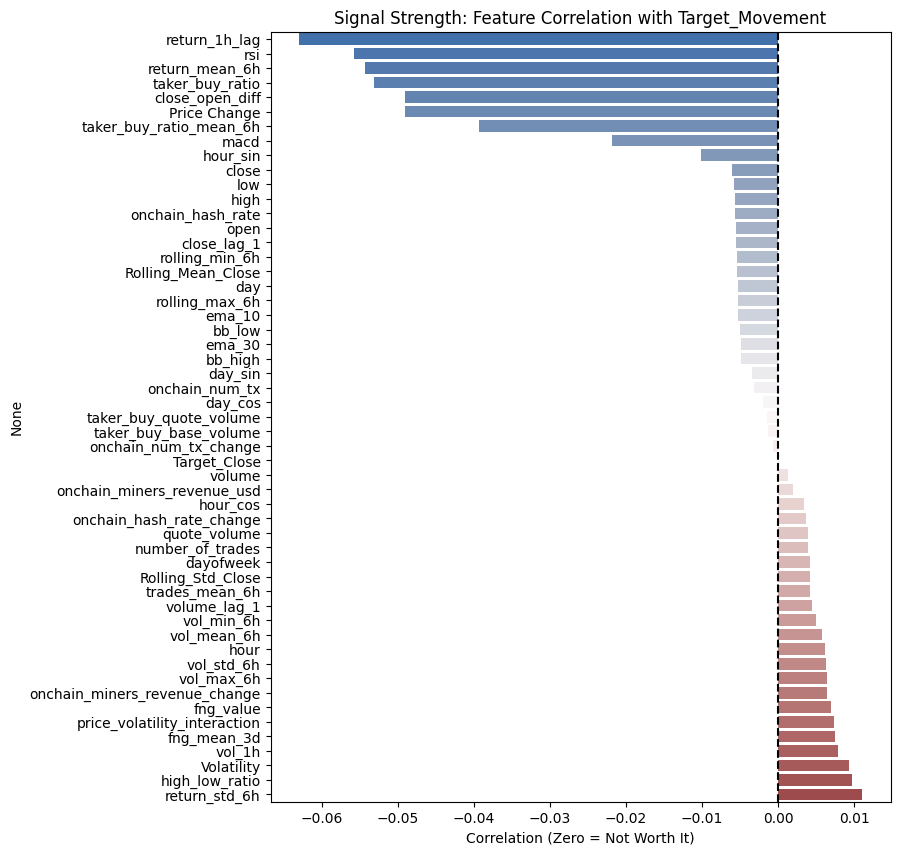

In [10]:
plt.figure(figsize=(8, 10))
sb.barplot(x=target_corr.values, y=target_corr.index, palette="vlag")
plt.axvline(0, color="black", linestyle="--")
plt.title("Signal Strength: Feature Correlation with Target_Movement")
plt.xlabel("Correlation (Zero = Not Worth It)")
plt.show()

These features need to be dropped after above visual 

In [11]:
dropped = ["close_open_diff", 
"day", 
"fng_value", 
"fng_mean_3d", 
"onchain_num_tx_change", 
"onchain_hash_rate_change", 
"onchain_miners_revenue_change"
]

In [12]:
df = old_df.drop(columns=dropped)

Now we need to convert doller into percentage

In [13]:
df["candle_body_pct"] = (df["close"] - df["open"]) / df["open"]
df["hl_range_pct"] = (df["high"] - df["low"]) / df["close"]

In [14]:
df["sma_10_dist_pct"] = (old_df["close"] - old_df["Rolling_Mean_Close"]) / old_df["Rolling_Mean_Close"]
df["ema_10_dist_pct"] = (old_df["close"] - old_df["ema_10"]) / old_df["ema_10"]
df["ema_30_dist_pct"] = (old_df["close"] - old_df["ema_30"]) / old_df["ema_30"]


In [15]:
df["bb_width_pct"] = (df["bb_high"] - df["bb_low"]) / df["close"]
df["bb_pct_b"] = (df["close"] - df["bb_low"]) / (df["bb_high"] - df["bb_low"])

In [16]:
df["return_1h"] = df["close"].pct_change(1)
df["return_lag_1"] = df["return_1h"].shift(1)

In [17]:
df.columns

Index(['timestamp', 'open', 'high', 'low', 'close', 'volume', 'quote_volume',
       'number_of_trades', 'taker_buy_base_volume', 'taker_buy_quote_volume',
       'taker_buy_ratio', 'onchain_num_tx', 'onchain_hash_rate',
       'onchain_miners_revenue_usd', 'Price Change', 'Volatility',
       'high_low_ratio', 'Rolling_Mean_Close', 'Rolling_Std_Close',
       'rolling_max_6h', 'rolling_min_6h', 'Target_Close', 'Target_Movement',
       'Target_Return', 'vol_1h', 'vol_mean_6h', 'vol_std_6h', 'vol_max_6h',
       'vol_min_6h', 'return_1h_lag', 'return_mean_6h', 'return_std_6h',
       'hour', 'dayofweek', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
       'rsi', 'macd', 'bb_high', 'bb_low', 'ema_10', 'ema_30', 'close_lag_1',
       'volume_lag_1', 'price_volatility_interaction',
       'taker_buy_ratio_mean_6h', 'trades_mean_6h', 'candle_body_pct',
       'hl_range_pct', 'sma_10_dist_pct', 'ema_10_dist_pct', 'ema_30_dist_pct',
       'bb_width_pct', 'bb_pct_b', 'return_1h', 'return_la

Now we are going to use chronological 3 way split 

In [18]:
df = df.replace([np.inf, -np.inf], np.nan).fillna(0.0)

In [19]:
n = len(df)

In [20]:
train_end = int(n * 0.60)
val_end = train_end + 1 + int(n * 0.20)

In [21]:
train_df = df.iloc[:train_end]
val_df = df.iloc[train_end + 1 : val_end]
holdout_df = df.iloc[val_end + 1:]

Training the model

In [22]:
features_col = [col for col in df.columns if col not in ["timestamp", "Target_Movement", "Target_Return", "Target_Close"]]

In [23]:
from xgboost import XGBClassifier, XGBRegressor

In [24]:
reg = XGBRegressor(
    objective = "reg:pseudohubererror",
    learning_rate = 0.015,
    max_depth = 3,
    min_child_weight = 25,
    reg_lambda = 5.0
)


In [25]:
clf = XGBClassifier(
    eval_metric = "logloss",
    learning_rate = 0.015,
    max_depth = 4,
    min_child_weight = 20,
    reg_lambda = 5.0,
    reg_alpha = 2.0
)

In [26]:
reg.fit(train_df[features_col], train_df["Target_Return"])
clf.fit(train_df[features_col], train_df["Target_Movement"])

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.015, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=20, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [27]:
val_pred_returns = reg.predict(val_df[features_col])
val_pred_prob = clf.predict_proba(val_df[features_col])[:, 1]
val_pred_dir = (val_pred_prob >= 0.50).astype(int)

Validation

In [28]:
from sklearn.metrics import accuracy_score, f1_score, log_loss, mean_squared_error

In [29]:
y_true_dir = val_df["Target_Movement"].astype(int).values
y_true_ret = val_df["Target_Return"].values

In [30]:
acc = accuracy_score(y_true_dir, val_pred_dir) * 100.0
macro_f1 = f1_score(y_true_dir, val_pred_dir, average="macro")
loss = log_loss(y_true_dir, val_pred_prob)

In [31]:
reg_dir_hit = np.mean((val_pred_returns >= 0) == (y_true_ret >= 0)) * 100.0

In [32]:
print(f"Classifier Accuracy: {acc:.2f}%")
print(f"Classifier Macro F1: {macro_f1:.4f}")
print(f"Classifier Log-Loss: {loss:.4f}  (Baseline coin-flip is 0.6931)")
print(f"Regressor Directional Hit: {reg_dir_hit:.2f}%")

Classifier Accuracy: 52.86%
Classifier Macro F1: 0.5236
Classifier Log-Loss: 0.6908  (Baseline coin-flip is 0.6931)
Regressor Directional Hit: 50.74%


Now we are going to introduce fee in this training

In [33]:
MIN_HURDLE = 0.00139951

In [34]:
train_rets = train_df["Target_Return"].values
train_weights = np.clip(np.abs(train_rets) / MIN_HURDLE, 0.25, 3.0)

In [35]:
clf_cost_aware = XGBClassifier(
    n_estimators=250,        # Number of trees to build (Default is 100; 250 gives deeper learning)
    learning_rate=0.015,     # Step size per tree
    max_depth=4,             # Tree depth (prevents memorizing noise)
    min_child_weight=20,     # Minimum 20 candles required to make a split
    subsample=0.80,          # Randomly picks 80% of rows per tree (Bagging: prevents overfitting to specific weeks)
    colsample_bytree=0.70,   # Randomly picks 70% of features per tree (Stops one feature from dominating)
    gamma=0.20,              # Minimum gain required to split a node (Tree pruning)
    reg_alpha=2.0,           # L1 Regularization (forces dead features to 0)
    reg_lambda=5.0,          # L2 Regularization (shrinks extreme weights)
    random_state=42,         # Ensures identical, reproducible results every time you run it
    n_jobs=-1,               # Uses all your CPU cores to train in seconds
    eval_metric="logloss"    # Optimizes probability calibration
)

In [36]:
clf_cost_aware.fit(train_df[features_col], 
train_df["Target_Movement"], sample_weight=train_weights)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=0.2, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.015, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=20, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=250,
              n_jobs=-1, num_parallel_tree=None, random_state=42, ...)

In [37]:
val_pred2_prob = clf_cost_aware.predict_proba(val_df[features_col])[:, 1]
val_pred2_dir = (val_pred2_prob >= 0.50).astype(int)

In [38]:
acc = accuracy_score(y_true_dir, val_pred2_dir) * 100.0
macro_f1 = f1_score(y_true_dir, val_pred2_dir, average="macro")
loss = log_loss(y_true_dir, val_pred2_prob)
print(f"Classifier Accuracy: {acc:.2f}%")
print(f"Classifier Macro F1: {macro_f1:.4f}")
print(f"Classifier Log-Loss: {loss:.4f}  (Baseline coin-flip is 0.6931)")

Classifier Accuracy: 52.19%
Classifier Macro F1: 0.5078
Classifier Log-Loss: 0.6936  (Baseline coin-flip is 0.6931)


Now we are going to see how much my model is confident in up and down

In [39]:
q_high = np.quantile(val_pred2_prob, 0.75) 
q_low = np.quantile(val_pred2_prob, 0.25) 

In [40]:
high_conv_mask = (val_pred2_prob >= q_high) | (val_pred2_prob <= q_low)

In [41]:
high_conv_acc = accuracy_score(y_true_dir[high_conv_mask], val_pred2_dir[high_conv_mask]) * 100.0
print(f"Standard Accuracy (All hours):          {acc:.2f}%")
print(f"High-Conviction Accuracy (Top 50% calls): {high_conv_acc:.2f}%")


Standard Accuracy (All hours):          52.19%
High-Conviction Accuracy (Top 50% calls): 53.64%


5-fold Walk forward validation

In [42]:
import src.backtesting
from experiments.backtesting.walk_forward_validate import run_walk_forward_validation

c:\Users\2335m\miniconda3\envs\mudra\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [43]:
all_weights = np.clip(np.abs(df["Target_Return"].values) / MIN_HURDLE, 0.25, 3.0)

In [44]:
wf_results_df = run_walk_forward_validation(
    df=df,
    model=clf_cost_aware,
    feature_cols=features_col,
    threshold=0.50,
    sample_weight=all_weights
)
display(wf_results_df)

[INFO] Evaluating Window 1/5 (2022-07-09 09:00:00 -> 2023-04-26 13:00:00)...
[INFO] Evaluating Window 2/5 (2023-04-26 14:00:00 -> 2024-02-11 11:00:00)...
[INFO] Evaluating Window 3/5 (2024-02-11 12:00:00 -> 2024-11-28 09:00:00)...
[INFO] Evaluating Window 4/5 (2024-11-28 10:00:00 -> 2025-09-15 07:00:00)...
[INFO] Evaluating Window 5/5 (2025-09-15 08:00:00 -> 2026-07-06 08:00:00)...


,window,period_start,period_end,num_trades,win_rate_pct,total_return_pct,buy_hold_return_pct,sharpe_ratio_annualized
0,1,2022-07-09 09:00:00,2023-04-26 13:00:00,435,40.92,-35.47,79.98,-4.954
1,2,2023-04-26 14:00:00,2024-02-11 11:00:00,244,58.20,-11.09,69.78,-1.727
2,3,2024-02-11 12:00:00,2024-11-28 09:00:00,448,54.24,-10.39,56.36,-0.650
3,4,2024-11-28 10:00:00,2025-09-15 07:00:00,417,39.81,-38.87,5.62,-7.070
4,5,2025-09-15 08:00:00,2026-07-06 08:00:00,213,43.66,-21.75,-10.38,-2.319


Because my model over trade we are going to introduce platt / sigmoid probability calibration

In [45]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import log_loss, brier_score_loss

In [46]:
calibrated_clf = CalibratedClassifierCV(
    estimator=clf_cost_aware,
    method="sigmoid",
    cv=TimeSeriesSplit(n_splits=5),
    n_jobs=-1,
    ensemble=True
)

In [47]:
calibrated_clf.fit(train_df[features_col], train_df["Target_Movement"])

CalibratedClassifierCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
                       estimator=XGBClassifier(base_score=None, booster=None,
                                               callbacks=None,
                                               colsample_bylevel=None,
                                               colsample_bynode=None,
                                               colsample_bytree=0.7,
                                               device=None,
                                               early_stopping_rounds=None,
                                               enable_categorical=False,
                                               eval_metric='logloss',
                                               feature_types=None, gamma=0.2,
                                               grow_policy=None,
                                               importance_type=None,
                                               interaction_constraints=None,
                                               learning_rate=0.015,
                                               max_bin=None,
                                               max_cat_threshold=None,
                                               max_cat_to_onehot=None,
                                               max_delta_step=None, max_depth=4,
                                               max_leaves=None,
                                               min_child_weight=20, missing=nan,
                                               monotone_constraints=None,
                                               multi_strategy=None,
                                               n_estimators=250, n_jobs=-1,
                                               num_parallel_tree=None,
                                               random_state=42, ...),
                       n_jobs=-1)

In [48]:
raw_probs = clf_cost_aware.predict_proba(val_df[features_col])[:, 1]
cal_probs = calibrated_clf.predict_proba(val_df[features_col])[:, 1]
print(f"Raw Log-Loss:           {log_loss(y_true_dir, raw_probs):.4f}")
print(f"Calibrated Log-Loss:    {log_loss(y_true_dir, cal_probs):.4f} (Closer to 0 is better)")
print(f"Raw Brier Score:        {brier_score_loss(y_true_dir, raw_probs):.4f}")
print(f"Calibrated Brier Score: {brier_score_loss(y_true_dir, cal_probs):.4f} (Lower is better)")

Raw Log-Loss:           0.6936
Calibrated Log-Loss:    0.6911 (Closer to 0 is better)
Raw Brier Score:        0.2502
Calibrated Brier Score: 0.2490 (Lower is better)


Again we are going to back test after calibrating

In [49]:
from src.backtesting import run_backtest, compute_metrics

In [50]:
threshold_results = []
for thresh in [0.50, 0.51, 0.52, 0.53]:
    ec, tl = run_backtest(
        val_df, 
        calibrated_clf, 
        threshold=thresh, 
        feature_cols=features_col
    )
    m = compute_metrics(ec, tl, val_df)
    threshold_results.append({
        "Threshold": thresh,
        "Trades": m["num_trades"],
        "Win Rate (%)": round(m["win_rate_pct"], 2),
        "Total Return (%)": round(m["total_return_pct"], 2),
        "Buy & Hold (%)": round(m["bh_return_pct"], 2),
        "Max Drawdown (%)": round(m["max_drawdown_pct"], 2),
        "Sharpe": round(m["sharpe_annualized"], 2)
    })

In [51]:
threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Threshold,Trades,Win Rate (%),Total Return (%),Buy & Hold (%),Max Drawdown (%),Sharpe
0,0.50,1125,53.07,-67.89,20.3,-69.70,-4.37
1,0.51,1127,50.13,-70.99,20.3,-73.16,-5.03
2,0.52,1082,50.18,-67.15,20.3,-68.29,-4.96
3,0.53,1058,48.11,-69.72,20.3,-70.38,-5.83


Now we are going to use significant test file

In [52]:
ec_50, tl_50 = run_backtest(
    val_df, 
    calibrated_clf, 
    threshold=0.50, 
    feature_cols=features_col
)

In [53]:
from experiments.backtesting.significance_test import evaluate_trade_significance

In [54]:
sig_report = evaluate_trade_significance(tl_50, alpha=0.05)


[STATISTIC] Total Trades: 1125 | Wins: 597 | Win Rate: 53.1%
[STATISTIC] Binomial Test vs p=0.5 (H1: win rate > 50%): p-value = 0.0213
  -> Significant at alpha=0.05
[STATISTIC] Gross Per-Trade Return: mean=0.042%, 95% Bootstrap CI=[-0.006%, 0.089%]
  -> CI spans 0 (insufficient evidence of gross edge)
[STATISTIC] Net Per-Trade Return (Post-Friction): mean=-0.098%, 95% Bootstrap CI=[-0.146%, -0.051%]
  -> Net CI spans 0 (edge fully consumed by transaction friction)


In [55]:
prob_series = pd.Series(cal_probs)
print(prob_series.describe(percentiles=[0.50, 0.75, 0.85, 0.90, 0.95, 0.99]))

count    6982.000000
mean        0.502617
std         0.050557
min         0.378157
50%         0.508735
75%         0.544246
85%         0.557152
90%         0.565483
95%         0.576374
99%         0.594850
max         0.618292
dtype: float64


In [56]:
high_conv_results = []
for thresh in [0.54, 0.55, 0.56, 0.57, 0.58]:
    ec, tl = run_backtest(
        val_df, 
        calibrated_clf, 
        threshold=thresh, 
        feature_cols=features_col
    )
    m = compute_metrics(ec, tl, val_df)
    high_conv_results.append({
        "Threshold": thresh,
        "Trades": m["num_trades"],
        "Win Rate (%)": round(m["win_rate_pct"], 2),
        "Total Return (%)": round(m["total_return_pct"], 2),
        "Buy & Hold (%)": round(m["bh_return_pct"], 2),
        "Max Drawdown (%)": round(m["max_drawdown_pct"], 2),
        "Sharpe": round(m["sharpe_annualized"], 2)
    })
high_conv_df = pd.DataFrame(high_conv_results)
display(high_conv_df)

,Threshold,Trades,Win Rate (%),Total Return (%),Buy & Hold (%),Max Drawdown (%),Sharpe
0,0.54,982,46.74,-61.09,20.3,-62.40,-5.22
1,0.55,838,44.03,-58.49,20.3,-60.06,-5.82
2,0.56,610,43.28,-40.87,20.3,-41.56,-4.76
3,0.57,385,39.48,-38.95,20.3,-39.00,-5.98
4,0.58,193,33.68,-26.03,20.3,-26.37,-5.86


Now we are going to use and test hysteresis across different entry threshold

In [57]:
from src.backtesting import _simulate_from_signals

In [58]:
hysteresis_results = []
for entry_thresh in [0.52, 0.53, 0.54, 0.55]:
    signals = np.zeros(len(val_df), dtype=int)
    pos = 0
    for i, p in enumerate(cal_probs):
        if pos == 0 and p >= entry_thresh:
            pos = 1  # Enter on high conviction
        elif pos == 1 and p < 0.50:
            pos = 0  # Exit only when trend flips bearish
        signals[i] = pos
        
    ec_h, tl_h = _simulate_from_signals(val_df, signals)
    m_h = compute_metrics(ec_h, tl_h, val_df)
    
    hysteresis_results.append({
        "Entry Threshold": entry_thresh,
        "Exit Threshold": 0.50,
        "Trades": m_h["num_trades"],
        "Win Rate (%)": round(m_h["win_rate_pct"], 2),
        "Total Return (%)": round(m_h["total_return_pct"], 2),
        "Buy & Hold (%)": round(m_h["bh_return_pct"], 2),
        "Max Drawdown (%)": round(m_h["max_drawdown_pct"], 2),
        "Sharpe": round(m_h["sharpe_annualized"], 2)
    })

In [59]:
hyst_df = pd.DataFrame(hysteresis_results)
display(hyst_df)

,Entry Threshold,Exit Threshold,Trades,Win Rate (%),Total Return (%),Buy & Hold (%),Max Drawdown (%),Sharpe
0,0.52,0.5,925,56.97,-55.22,20.3,-58.83,-3.32
1,0.53,0.5,820,58.66,-54.57,20.3,-58.43,-3.37
2,0.54,0.5,704,59.52,-43.12,20.3,-49.06,-2.54
3,0.55,0.5,555,57.84,-41.20,20.3,-47.92,-2.63


Now we are going test if higher entry conviction and slightly wider exit will drop the fees cost

In [60]:
fine_hyst_results = []
for entry_thresh in [0.55, 0.56, 0.57, 0.58]:
    for exit_thresh in [0.50, 0.48]:
        signals = np.zeros(len(val_df), dtype=int)
        pos = 0
        for i, p in enumerate(cal_probs):
            if pos == 0 and p >= entry_thresh:
                pos = 1  # Enter only on top-quantile conviction
            elif pos == 1 and p < exit_thresh:
                pos = 0  # Exit only when trend flips firmly bearish
            signals[i] = pos
            
        ec_h, tl_h = _simulate_from_signals(val_df, signals)
        m_h = compute_metrics(ec_h, tl_h, val_df)
        
        fine_hyst_results.append({
            "Entry": entry_thresh,
            "Exit": exit_thresh,
            "Trades": m_h["num_trades"],
            "Win Rate (%)": round(m_h["win_rate_pct"], 2),
            "Total Return (%)": round(m_h["total_return_pct"], 2),
            "Buy & Hold (%)": round(m_h["bh_return_pct"], 2),
            "Max Drawdown (%)": round(m_h["max_drawdown_pct"], 2),
            "Sharpe": round(m_h["sharpe_annualized"], 2)
        })
fine_hyst_df = pd.DataFrame(fine_hyst_results)
display(fine_hyst_df)

,Entry,Exit,Trades,Win Rate (%),Total Return (%),Buy & Hold (%),Max Drawdown (%),Sharpe
0,0.55,0.50,555,57.84,-41.20,20.3,-47.92,-2.63
1,0.55,0.48,477,60.59,-27.22,20.3,-39.45,-1.40
2,0.56,0.50,408,59.80,-24.15,20.3,-29.69,-1.64
3,0.56,0.48,359,62.12,-17.66,20.3,-27.58,-0.99
4,0.57,0.50,271,57.56,-28.95,20.3,-32.61,-2.48
5,0.57,0.48,243,58.85,-24.83,20.3,-30.45,-1.89
6,0.58,0.50,146,52.74,-26.33,20.3,-27.41,-3.06
7,0.58,0.48,138,58.70,-24.30,20.3,-26.36,-2.55


Now we're going to focus in regression are introducing Uh pasudo harbor error and also by introducing fees

In [61]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

In [62]:
reg_cost_aware = XGBRegressor(
    objective = "reg:pseudohubererror",
    n_estimators = 250,
    learning_rate = 0.015,
    max_depth = 4,
    subsample = 0.80,
    colsample_bytree = 0.70,
    random_state = 42,
    n_jobs = 1
)

In [63]:
reg_cost_aware.fit(train_df[features_col], train_df["Target_Return"], sample_weight=train_weights)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.015, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=4, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=250, n_jobs=1,
             num_parallel_tree=None, objective='reg:pseudohubererror', ...)

In [64]:
val_pred2_ret = reg_cost_aware.predict(val_df[features_col])

In [65]:
MAE = mean_absolute_error(val_df["Target_Return"], val_pred2_ret)
dir_hit_rate = (np.sign(val_pred2_ret) == np.sign(val_df["Target_Return"])).mean() * 100

In [66]:
print(MAE)
print(dir_hit_rate)

0.0031825342456824517
50.51561157261529


Now we are going to test our regression model bit we need to change its signal to 0 and 1 for that we are going to change the value by math formula where if predicted return price is smaller the fee hurdle signal will be 0 else 1.

In [71]:
val_ret_sig = (val_pred2_ret >= 0.0014).astype(int)

In [74]:
ec_reg, tl_reg = _simulate_from_signals(val_df, val_ret_sig)
mh_reg = compute_metrics(ec_reg, tl_reg, val_df)

In [75]:
print(mh_reg)

{'initial_capital': 10000.0, 'final_equity': 7562.02, 'total_return_pct': -24.38, 'bh_final_equity': 12030.14, 'bh_return_pct': 20.3, 'sharpe_annualized': -1.988, 'sortino_annualized': -0.662, 'max_drawdown_pct': -28.96, 'bh_max_drawdown_pct': -30.94, 'calmar_ratio': -0.842, 'win_rate_pct': 47.13, 'profit_factor': 0.62, 'num_trades': 157, 'avg_trade_return_pct': -0.172, 'exposure_pct': 4.64}


Now we are going to find which features are important for our model

In [94]:
clf_dic = {}
reg_dic = {}
imp_clf_fea = clf_cost_aware.feature_importances_
imp_reg_fea = reg_cost_aware.feature_importances_
clf_dic = dict(zip(features_col, imp_clf_fea))
reg_dic = dict(zip(features_col, imp_reg_fea))
print(sorted(clf_dic.items(), key = lambda x : x[1])[-10:])
print(sorted(reg_dic.items(), key = lambda x : x[1])[-10:])

[('volume', 0.019227771), ('return_std_6h', 0.020212604), ('return_mean_6h', 0.021007346), ('return_1h', 0.021316094), ('taker_buy_ratio', 0.021777144), ('ema_10_dist_pct', 0.028395306), ('Price Change', 0.028575787), ('return_1h_lag', 0.030165209), ('candle_body_pct', 0.030200336), ('sma_10_dist_pct', 0.041580647)]
[('vol_mean_6h', 0.020257492), ('taker_buy_base_volume', 0.020300716), ('bb_width_pct', 0.020420413), ('Volatility', 0.02045775), ('bb_high', 0.021072246), ('vol_min_6h', 0.02107426), ('ema_30', 0.022271203), ('rolling_min_6h', 0.02284561), ('hour_cos', 0.024820419), ('Rolling_Mean_Close', 0.025005909)]


After understanding which features are important and helping our model to understand also as we can see that every feature is important so we are not going to remove anything.

Now we are going to combine our these two different model to make duel-head model

In [96]:
fused_signals = ((cal_probs >= 0.56) & (val_pred2_ret >= 0.0014)).astype(int)

In [98]:
new_ec, new_tl = _simulate_from_signals(val_df, fused_signals)
new_mh = compute_metrics(new_ec, new_tl, val_df)
print(new_mh)

{'initial_capital': 10000.0, 'final_equity': 9814.52, 'total_return_pct': -1.85, 'bh_final_equity': 12030.14, 'bh_return_pct': 20.3, 'sharpe_annualized': -0.381, 'sortino_annualized': -0.053, 'max_drawdown_pct': -5.18, 'bh_max_drawdown_pct': -30.94, 'calmar_ratio': -0.358, 'win_rate_pct': 55.0, 'profit_factor': 0.85, 'num_trades': 40, 'avg_trade_return_pct': -0.043, 'exposure_pct': 0.67}


Now we're going to do hysteresis

In [103]:
hys_sig = np.zeros(len(val_df), dtype=int)
pos = 0
for pred, row in enumerate(val_df.itertuples()):
    if pos == 0:
        if cal_probs[pred] >= 0.56 and val_pred2_ret[pred] >= 0.0014:
            pos = 1
    elif pos == 1:
        if cal_probs[pred] < 0.48:
            pos = 0
    hys_sig[pred] = pos
print(hys_sig)

[0 0 0 ... 0 0 0]


In [108]:
new2_ec, new2_tl = _simulate_from_signals(val_df, hys_sig)
new2_mh = compute_metrics(new2_ec, new2_tl, val_df)
print(new2_mh)

{'initial_capital': 10000.0, 'final_equity': 10092.22, 'total_return_pct': 0.92, 'bh_final_equity': 12030.14, 'bh_return_pct': 20.3, 'sharpe_annualized': 0.164, 'sortino_annualized': 0.036, 'max_drawdown_pct': -6.68, 'bh_max_drawdown_pct': -30.94, 'calmar_ratio': 0.138, 'win_rate_pct': 72.22, 'profit_factor': 1.05, 'num_trades': 36, 'avg_trade_return_pct': 0.035, 'exposure_pct': 3.02}


Now we're going to check the binomial P value and bootstrap confidence interval

In [109]:
from experiments.backtesting.significance_test import evaluate_trade_significance

In [110]:
sig_result = evaluate_trade_significance(new2_tl)
print(sig_result)

[STATISTIC] Total Trades: 36 | Wins: 26 | Win Rate: 72.2%
[STATISTIC] Binomial Test vs p=0.5 (H1: win rate > 50%): p-value = 0.0057
  -> Significant at alpha=0.05
[STATISTIC] Gross Per-Trade Return: mean=0.175%, 95% Bootstrap CI=[-0.291%, 0.595%]
  -> CI spans 0 (insufficient evidence of gross edge)
[STATISTIC] Net Per-Trade Return (Post-Friction): mean=0.035%, 95% Bootstrap CI=[-0.430%, 0.454%]
  -> Net CI spans 0 (edge fully consumed by transaction friction)
{'total_trades': 36, 'wins': 26, 'win_rate_pct': 72.22, 'binomial_pvalue': 0.00567, 'is_significant': True, 'gross_mean_pct': 0.175, 'gross_ci_95': (-0.291, 0.595), 'net_mean_pct': 0.035, 'net_ci_95': (-0.43, 0.454)}


Now We are going test out model against the untouched data

In [111]:
holdout_probs = calibrated_clf.predict_proba(holdout_df[features_col])[:, 1]
holdout_pred_ret = reg_cost_aware.predict(holdout_df[features_col])

In [112]:
holdout_sig = np.zeros(len(holdout_df), dtype=int)
pos = 0
for pred, row in enumerate(holdout_df.itertuples()):
    if pos == 0:
        if holdout_probs[pred] >= 0.56 and holdout_pred_ret[pred] >= 0.0014:
            pos = 1
    elif pos == 1:
        if holdout_probs[pred] < 0.48:
            pos = 0
    holdout_sig[pred] = pos

hold_ec, hold_tl = _simulate_from_signals(holdout_df, holdout_sig)
hold_mh = compute_metrics(hold_ec, hold_tl, holdout_df)
print(hold_mh)

{'initial_capital': 10000.0, 'final_equity': 10223.06, 'total_return_pct': 2.23, 'bh_final_equity': 5466.59, 'bh_return_pct': -45.33, 'sharpe_annualized': 0.332, 'sortino_annualized': 0.082, 'max_drawdown_pct': -10.19, 'bh_max_drawdown_pct': -53.74, 'calmar_ratio': 0.219, 'win_rate_pct': 71.88, 'profit_factor': 1.15, 'num_trades': 32, 'avg_trade_return_pct': 0.08, 'exposure_pct': 2.72}


In [113]:
hold_sig_result = evaluate_trade_significance(hold_tl)
print(hold_sig_result)

[STATISTIC] Total Trades: 32 | Wins: 23 | Win Rate: 71.9%
[STATISTIC] Binomial Test vs p=0.5 (H1: win rate > 50%): p-value = 0.0100
  -> Significant at alpha=0.05
[STATISTIC] Gross Per-Trade Return: mean=0.220%, 95% Bootstrap CI=[-0.315%, 0.680%]
  -> CI spans 0 (insufficient evidence of gross edge)
[STATISTIC] Net Per-Trade Return (Post-Friction): mean=0.080%, 95% Bootstrap CI=[-0.454%, 0.539%]
  -> Net CI spans 0 (edge fully consumed by transaction friction)
{'total_trades': 32, 'wins': 23, 'win_rate_pct': 71.88, 'binomial_pvalue': 0.01003, 'is_significant': True, 'gross_mean_pct': 0.22, 'gross_ci_95': (-0.315, 0.68), 'net_mean_pct': 0.08, 'net_ci_95': (-0.454, 0.539)}
